# IXI Brain Volumes

`results/volumes.csv` holds one brain volume for each of the 581 IXI T1 scans. `process.py` skull-strips the scan with FreeSurfer `mri_synthstrip`, then counts nonzero voxels times the voxel volume. The mask still contains cerebrospinal fluid, so the number is the whole stripped brain.

The plots below follow the matplotlib style in `~/gcinfo/README.md`: default figure size, bar charts for sites, sex, and ethnicity, line charts where the x axis is ordered, the legend under the axes, and a source line under the legend.

Run this notebook from the repository root so `results/volumes.csv` and `data/IXI.xls` resolve.

In [ ]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / "results" / "volumes.csv").exists():
    ROOT = ROOT.parent

SOURCE = (
    "Source: IXI Dataset, brain-development.org.\n"
    "Volumes from FreeSurfer SynthStrip.\n"
    "Hoopes et al., NeuroImage 260 (2022) 119474."
)

SITE_ORDER = ["Guys", "HH", "IOP"]
SITE_NAMES = {
    "Guys": "Guy's Hospital",
    "HH": "Hammersmith Hospital",
    "IOP": "Institute of Psychiatry",
}


def show_plot(ax, source, legend=False):
    """Apply the gcinfo README plot style, then display the figure."""
    if legend:
        ax.legend(
            title=None,
            loc="upper center",
            bbox_to_anchor=(0.5, -0.22),
            ncol=1,
            frameon=True,
        )
    # A three line citation overlaps the legend at the style guide's y=-0.03.
    source_y = -0.12 if legend else -0.03
    plt.figtext(
        0.5, source_y,
        source,
        ha="center",
        fontsize=8,
        style="italic",
    )
    plt.subplots_adjust(bottom=0.3)
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


volumes = pd.read_csv(ROOT / "results" / "volumes.csv")
volumes = volumes.loc[volumes["status"].eq("ok")].copy()

print(f"{len(volumes)} scans with status ok")
print(volumes["volume_ml"].describe().round(1).to_string())
print()
print(volumes.groupby("site")["volume_ml"].agg(["count", "mean", "std", "min", "median", "max"]).round(1).reindex(SITE_ORDER).to_string())

581 scans with status ok
count     581.0
mean     1527.0
std       155.9
min      1154.2
25%      1412.5
50%      1519.1
75%      1637.0
max      2105.2

      count    mean    std     min  median     max
site                                              
Guys    322  1536.1  157.2  1154.2  1522.5  2105.2
HH      185  1518.2  150.6  1179.5  1520.4  1915.9
IOP      74  1509.6  162.0  1181.0  1494.0  1926.1


## How the volumes are spread

Brain volume is a continuous measure, so the count in each 50 ml band is a line.

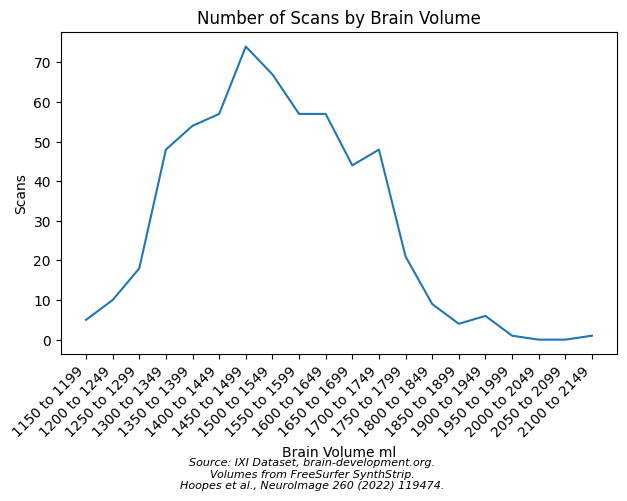

In [ ]:
bin_edges = list(range(1150, 2151, 50))
bands = pd.cut(volumes["volume_ml"], bins=bin_edges, right=False)
band_counts = bands.value_counts(sort=False)
band_labels = [f"{int(band.left)} to {int(band.right) - 1}" for band in band_counts.index]

fig, ax = plt.subplots()
ax.plot(band_labels, band_counts.to_numpy(), linestyle="-")
ax.set_title("Number of Scans by Brain Volume")
ax.set_xlabel("Brain Volume ml")
ax.set_ylabel("Scans")
show_plot(ax, SOURCE)

## Scans and mean volume at each hospital

Site is a category, so both comparisons are bar charts. Guy's Hospital contributed the most scans. Mean volume differs only slightly across the three hospitals.

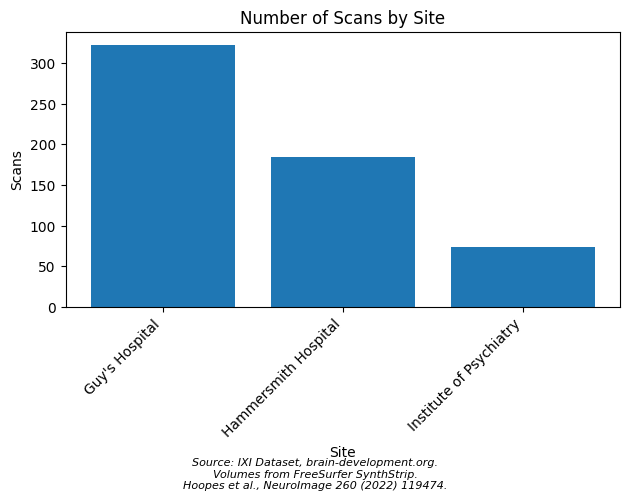

In [ ]:
site_counts = volumes["site"].value_counts().reindex(SITE_ORDER)
site_labels = [SITE_NAMES[site] for site in SITE_ORDER]

fig, ax = plt.subplots()
ax.bar(site_labels, site_counts.to_numpy())
ax.set_title("Number of Scans by Site")
ax.set_xlabel("Site")
ax.set_ylabel("Scans")
show_plot(ax, SOURCE)

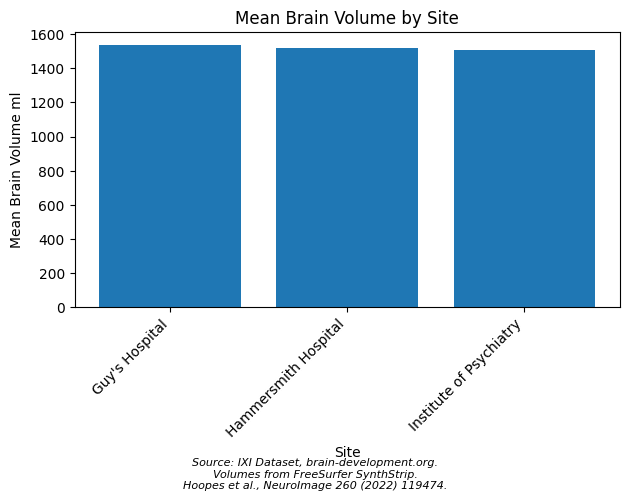

In [ ]:
site_means = volumes.groupby("site")["volume_ml"].mean().reindex(SITE_ORDER)

fig, ax = plt.subplots()
ax.bar(site_labels, site_means.to_numpy())
ax.set_title("Mean Brain Volume by Site")
ax.set_xlabel("Site")
ax.set_ylabel("Mean Brain Volume ml")
show_plot(ax, SOURCE)

## Age and sex from the IXI spreadsheet

`data/IXI.xls` sheet `Table` is joined on the numeric id inside `ixi_id`. Some ids appear twice. A second row is often blank, so the row with a height between 100 cm and 250 cm is kept. IXI219 has two filled rows with different ages, so that scan is left out of the age and sex plots. Scans with no spreadsheet row are left out as well.

In [ ]:
demo = pd.read_excel(ROOT / "data" / "IXI.xls", sheet_name="Table")
demo = demo.rename(columns={"SEX_ID (1=m, 2=f)": "sex_id"})
demo["plausible_height"] = demo["HEIGHT"].between(100, 250)

kept_rows = []
excluded_ids = []
for ixi_id, group in demo.groupby("IXI_ID", sort=False):
    filled = group.loc[group["plausible_height"]]
    chosen = filled if len(filled) else group
    same_sex = chosen["sex_id"].nunique(dropna=False) == 1
    same_age = chosen["AGE"].round(3).nunique(dropna=False) == 1
    if not same_sex or not same_age:
        excluded_ids.append(int(ixi_id))
        continue
    kept_rows.append(chosen.iloc[0])

demo_clean = pd.DataFrame(kept_rows)
volumes["id_num"] = volumes["ixi_id"].str.removeprefix("IXI").astype(int)
linked = volumes.merge(demo_clean, left_on="id_num", right_on="IXI_ID", how="left")

excluded_subjects = linked.loc[linked["id_num"].isin(excluded_ids), "subject"]
missing_demo = linked.loc[linked["IXI_ID"].isna() & ~linked["id_num"].isin(excluded_ids), "subject"]
print(f"spreadsheet rows kept: {len(demo_clean)}")
print(f"scans joined: {linked['IXI_ID'].notna().sum()} of {len(linked)}")
print(f"joined scans with age: {linked['AGE'].notna().sum()}")
print("scans left out because age or sex disagrees:")
print("\n".join(excluded_subjects.tolist()))
print("scans with no spreadsheet row:")
print("\n".join(missing_demo.tolist()))

spreadsheet rows kept: 592
scans joined: 565 of 581
joined scans with age: 562
scans left out because age or sex disagrees:
IXI219-Guys-0894-T1
scans with no spreadsheet row:
IXI081-Guys-0855-T1
IXI088-Guys-0758-T1
IXI117-Guys-0763-T1
IXI228-Guys-0822-T1
IXI333-IOP-0926-T1
IXI337-IOP-0929-T1
IXI340-IOP-0915-T1
IXI345-IOP-0928-T1
IXI347-IOP-0927-T1
IXI457-Guys-0984-T1
IXI589-Guys-1080-T1
IXI637-HH-2785-T1
IXI638-HH-2786-T1
IXI643-HH-2787-T1
IXI661-HH-2788-T1


## Volume by sex

Sex is a category. Male brains in this set are larger on average than female brains, and that gap is much wider than the gap between hospitals.

        count    mean    std     min  median     max
Male      253  1632.4  121.9  1315.6  1626.3  1953.7
Female    312  1439.2  119.4  1154.2  1438.7  1863.2


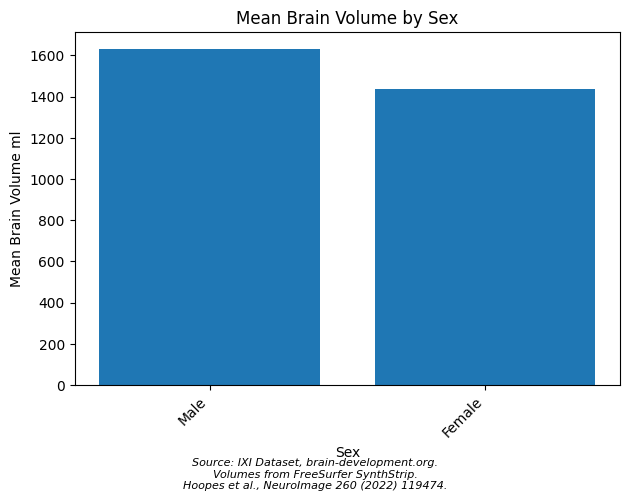

In [ ]:
sex_names = {1: "Male", 2: "Female"}
with_sex = linked.dropna(subset=["sex_id"]).copy()
with_sex["sex_id"] = with_sex["sex_id"].astype(int)
sex_summary = with_sex.groupby("sex_id")["volume_ml"].agg(["count", "mean", "std", "min", "median", "max"]).reindex([1, 2]).round(1)
sex_summary.index = [sex_names[i] for i in sex_summary.index]
print(sex_summary.to_string())

fig, ax = plt.subplots()
ax.bar(sex_summary.index, sex_summary["mean"].to_numpy())
ax.set_title("Mean Brain Volume by Sex")
ax.set_xlabel("Sex")
ax.set_ylabel("Mean Brain Volume ml")
show_plot(ax, SOURCE)

## Volume by age

Age moves in order, so mean volume in each five year group is a line, with one line for each sex. Groups run from 20 to 24 through 70 to 74. The handful of scans younger than 20 or older than 74 are omitted so each point rests on at least 10 scans.

          Male scans  Female scans    Male  Female
20 to 24          20            21  1643.5  1487.2
25 to 29          25            34  1646.2  1492.2
30 to 34          35            19  1642.6  1466.4
35 to 39          25            20  1654.6  1436.9
40 to 44          18            30  1680.3  1442.1
45 to 49          23            18  1649.1  1462.0
50 to 54          14            26  1638.2  1448.6
55 to 59          24            34  1605.1  1406.6
60 to 64          23            44  1616.2  1397.4
65 to 69          23            28  1595.0  1438.4
70 to 74          12            26  1600.5  1414.6
scans in the age plot: 542


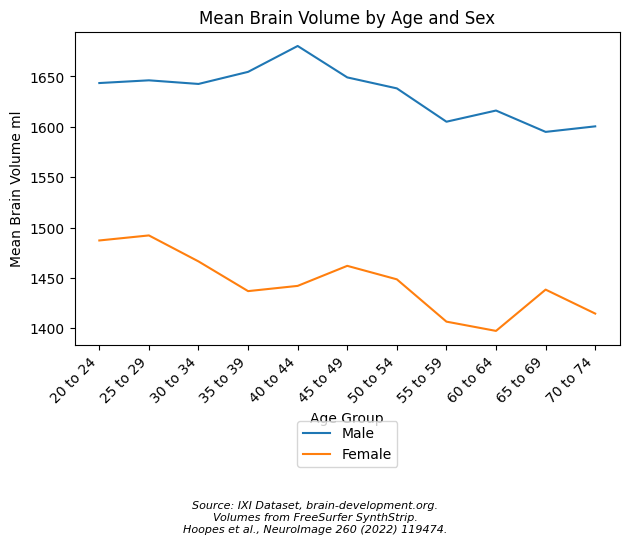

In [ ]:
with_age = linked.dropna(subset=["AGE", "sex_id"]).copy()
with_age["sex_id"] = with_age["sex_id"].astype(int)
with_age["age_start"] = (with_age["AGE"] // 5 * 5).astype(int)
with_age = with_age.loc[with_age["age_start"].between(20, 70)]

age_counts = with_age.groupby(["age_start", "sex_id"]).size().unstack()
age_means = with_age.groupby(["age_start", "sex_id"])["volume_ml"].mean().unstack().round(1)
age_table = age_means.copy()
age_table.columns = [sex_names[int(col)] for col in age_table.columns]
age_table.insert(0, "Male scans", age_counts[1].astype(int))
age_table.insert(1, "Female scans", age_counts[2].astype(int))
age_table.index = [f"{int(start)} to {int(start) + 4}" for start in age_table.index]
print(age_table.to_string())
print(f"scans in the age plot: {len(with_age)}")

age_labels = list(age_table.index)
fig, ax = plt.subplots()
ax.plot(age_labels, age_means[1].to_numpy(), linestyle="-", label="Male")
ax.plot(age_labels, age_means[2].to_numpy(), linestyle="-", label="Female")
ax.set_title("Mean Brain Volume by Age and Sex")
ax.set_xlabel("Age Group")
ax.set_ylabel("Mean Brain Volume ml")
show_plot(ax, SOURCE, legend=True)

## Volume by ethnicity

Ethnicity is a category, so the comparison is a bar chart. Names come from the `Ethnicity` sheet on the same join as age and sex. Code 0 is blank, and code 2 has no row on that sheet, so those scans stay out of the chart. White is most of the sample. The other named groups are much smaller, and the chart is the raw mean with no adjustment for age, sex, or height.


                        count    mean    std     min  median     max
White                     452  1534.7  154.6  1154.2  1526.8  1953.7
Asian or Asian British     50  1470.2  129.9  1181.0  1473.1  1775.2
Black or Black British     14  1425.1  154.8  1179.5  1393.6  1657.6
Chinese                    14  1559.0  144.1  1317.4  1568.9  1733.5
Other                      10  1453.8  137.1  1269.8  1434.9  1635.2
scans in the ethnicity plot: 540
scans with ethnic code 0: 10
scans with ethnic code 2: 15


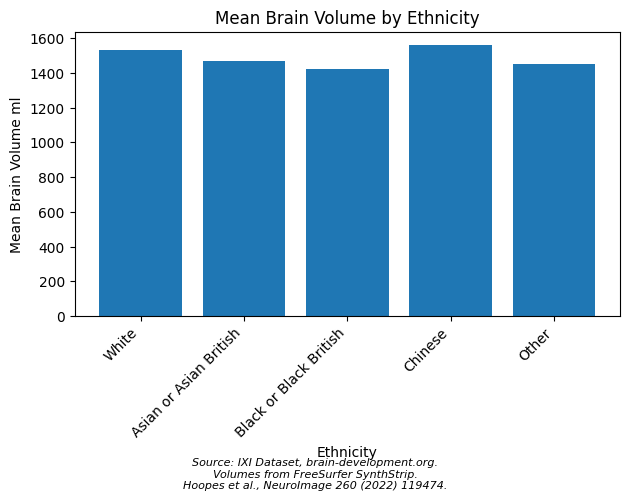

In [ ]:
ethnic = pd.read_excel(ROOT / "data" / "IXI.xls", sheet_name="Ethnicity")
ethnic_names = dict(zip(ethnic["ID"].astype(int), ethnic["ETHNIC"]))
ethnic_order = [1, 3, 4, 5, 6]

with_ethnic = linked.dropna(subset=["ETHNIC_ID"]).copy()
with_ethnic["ETHNIC_ID"] = with_ethnic["ETHNIC_ID"].astype(int)
with_ethnic = with_ethnic.loc[with_ethnic["ETHNIC_ID"].isin(ethnic_order)]

ethnic_summary = (
    with_ethnic.groupby("ETHNIC_ID")["volume_ml"]
    .agg(["count", "mean", "std", "min", "median", "max"])
    .reindex(ethnic_order)
    .round(1)
)
ethnic_summary.index = [ethnic_names[i] for i in ethnic_summary.index]
print(ethnic_summary.to_string())
print(f"scans in the ethnicity plot: {len(with_ethnic)}")
print(f"scans with ethnic code 0: {(linked['ETHNIC_ID'] == 0).sum()}")
print(f"scans with ethnic code 2: {(linked['ETHNIC_ID'] == 2).sum()}")

fig, ax = plt.subplots()
ax.bar(ethnic_summary.index, ethnic_summary["mean"].to_numpy())
ax.set_title("Mean Brain Volume by Ethnicity")
ax.set_xlabel("Ethnicity")
ax.set_ylabel("Mean Brain Volume ml")
show_plot(ax, SOURCE)


## Difference from White

Each bar is that group's mean brain volume minus the White mean, divided by the White mean. White is the reference, at about 1535 ml from 452 scans, and is left off the chart. The groups are the same named groups as the chart above. Those groups are much smaller, and the percentages use the raw means with no adjustment for age, sex, or height.

White mean: 1534.7 ml
                        count    mean  percent
Asian or Asian British     50  1470.2     -4.2
Black or Black British     14  1425.1     -7.1
Chinese                    14  1559.0      1.6
Other                      10  1453.8     -5.3


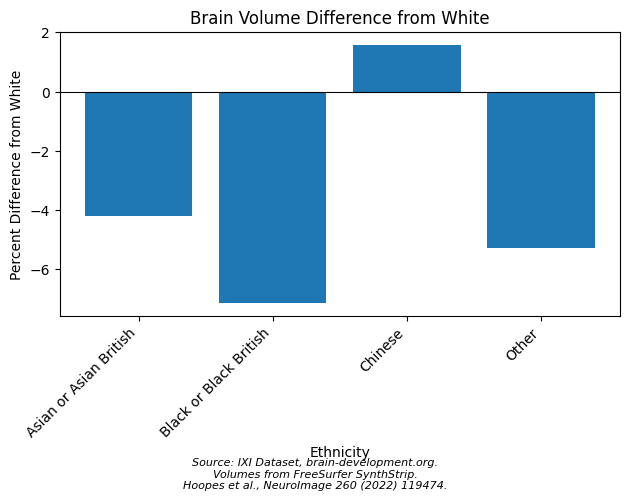

In [ ]:
white_mean = with_ethnic.loc[with_ethnic["ETHNIC_ID"].eq(1), "volume_ml"].mean()
other_order = [3, 4, 5, 6]
other = (
    with_ethnic.loc[with_ethnic["ETHNIC_ID"].isin(other_order)]
    .groupby("ETHNIC_ID")["volume_ml"]
    .agg(["count", "mean"])
    .reindex(other_order)
)
other["percent"] = (other["mean"] - white_mean) / white_mean * 100
other.index = [ethnic_names[i] for i in other.index]
other["count"] = other["count"].astype(int)
shown = other.copy()
shown["mean"] = shown["mean"].round(1)
shown["percent"] = shown["percent"].round(1)
print(f"White mean: {white_mean:.1f} ml")
print(shown.to_string())

fig, ax = plt.subplots()
ax.bar(other.index, other["percent"].to_numpy())
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Brain Volume Difference from White")
ax.set_xlabel("Ethnicity")
ax.set_ylabel("Percent Difference from White")
show_plot(ax, SOURCE)
